In [69]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

Загружаем датасет из файла

In [89]:
data=pd.read_csv("/content/Titanic-Dataset.xls")

In [90]:
data.head(10)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C


Видим, что у нас есть 3 столбца в которых есть пропуски (null значения)

In [91]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


Удаляем столбцы, которые на влияют на выживание пассажира

In [92]:
data.drop(["Embarked","Cabin","PassengerId","Name","Ticket"],axis="columns",inplace=True)

In [93]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  891 non-null    int64  
 1   Pclass    891 non-null    int64  
 2   Sex       891 non-null    object 
 3   Age       714 non-null    float64
 4   SibSp     891 non-null    int64  
 5   Parch     891 non-null    int64  
 6   Fare      891 non-null    float64
dtypes: float64(2), int64(4), object(1)
memory usage: 48.9+ KB


In [9]:
data["Age"].median()

28.0

Заполняем все пропуски в столбце "возраст" средним значением по столбцу

In [94]:
data["Age"] = data["Age"].fillna(data["Age"].median())

Визуализируем наши данные

In [97]:
# Таблица 1: Доля выживших в зависимости от Пола и Класса каюты
# Значения показывают вероятность выживания (от 0 до 1)
pivot_survival = pd.pivot_table(
    data,
    values='Survived',
    index='Sex',
    columns='Pclass',
    aggfunc='mean'
)
print("=== Доля выживших по Полу и Классу ===")
print(pivot_survival.round(3))

# Таблица 2: Средние показатели по классам кают
# Показывает, как класс влияет на возраст и стоимость билета
pivot_stats = data.groupby('Pclass').agg({
    'Age': 'mean',
    'Fare': 'mean',
    'Survived': 'mean'
}).round(2)
pivot_stats.rename(columns={'Survived': 'Survival_Rate'}, inplace=True)

print("\n=== Средние показатели по Классу каюты ===")
print(pivot_stats)

=== Доля выживших по Полу и Классу ===
Pclass      1      2      3
Sex                        
female  0.968  0.921  0.500
male    0.369  0.157  0.135

=== Средние показатели по Классу каюты ===
          Age   Fare  Survival_Rate
Pclass                             
1       36.81  84.15           0.63
2       29.77  20.66           0.47
3       25.93  13.68           0.24


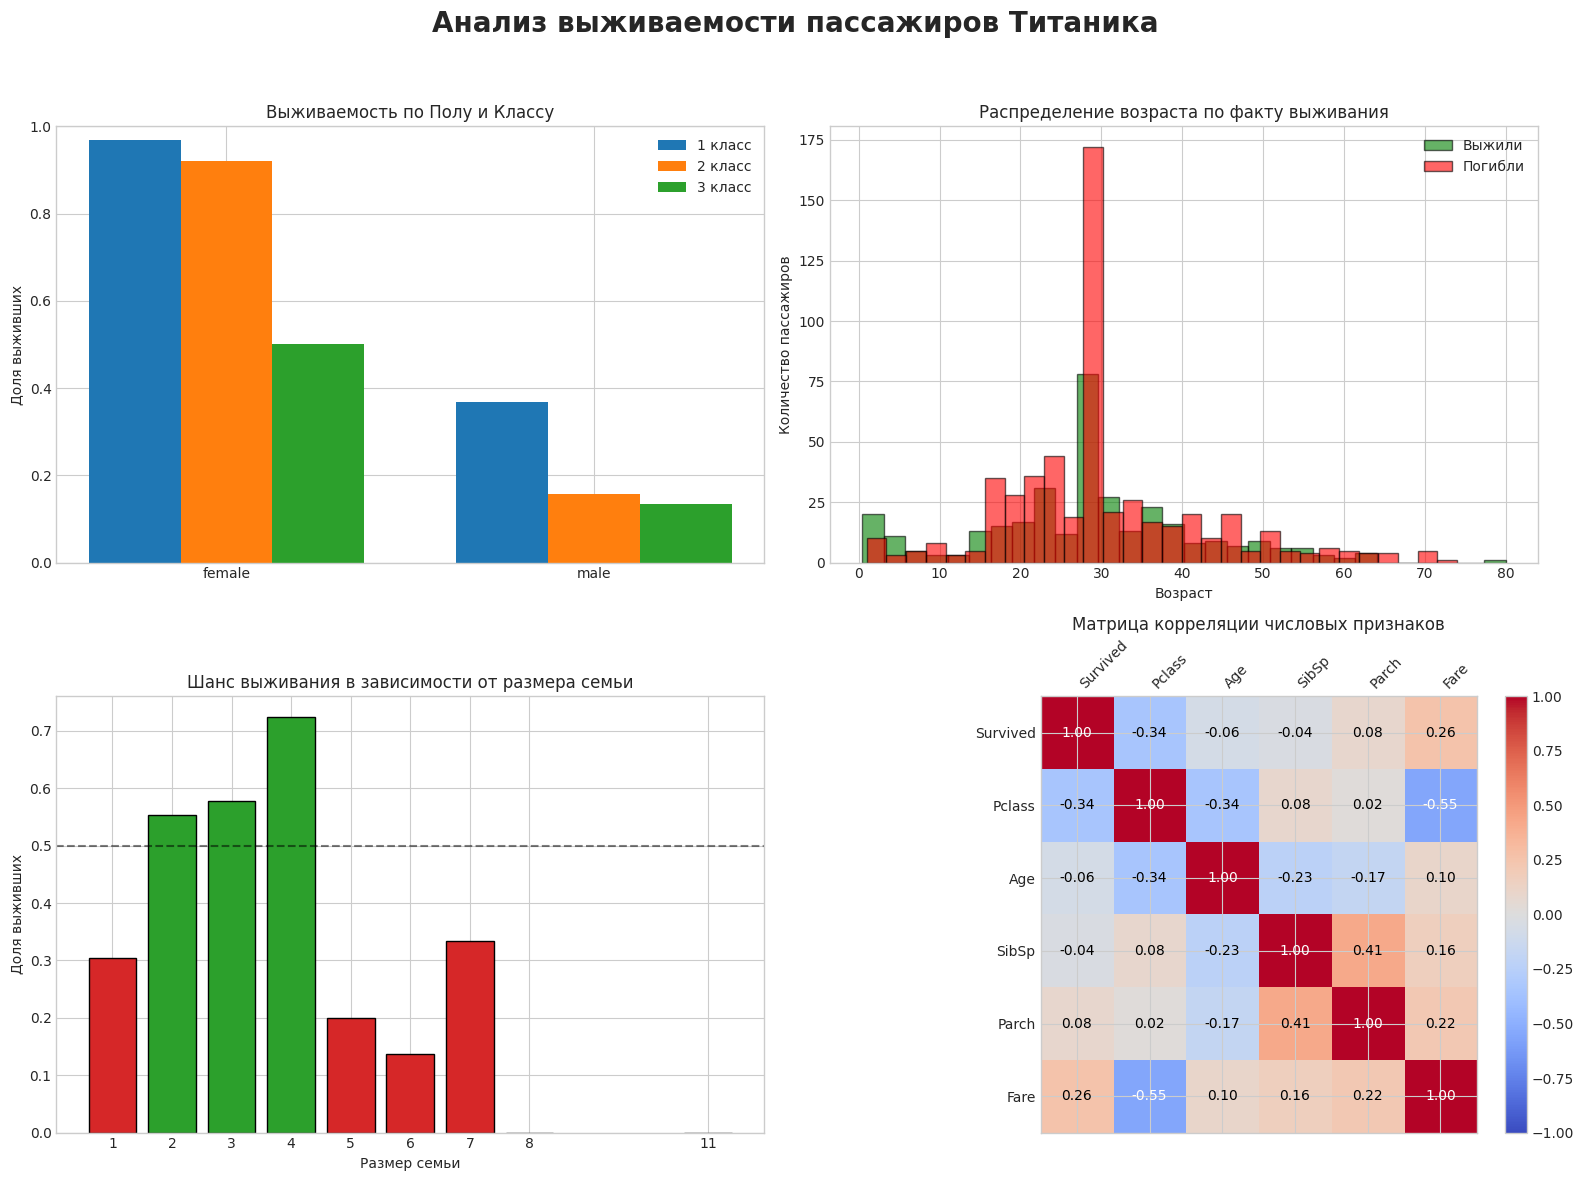

In [98]:
# Настройка стилей для красивого отображения (и поддержки кириллицы)
plt.style.use('seaborn-v0_8-whitegrid') # Или 'ggplot', если первый недоступен
plt.rcParams['font.family'] = 'DejaVu Sans' # Помогает избежать "кракозябр" в заголовках

fig = plt.figure(figsize=(16, 12))
fig.suptitle('Анализ выживаемости пассажиров Титаника', fontsize=20, fontweight='bold', y=0.98)

# --- График 1: Выживаемость по Полу и Классу (Группированная столбчатая диаграмма) ---
ax1 = plt.subplot(2, 2, 1)
survival_data = pivot_survival # Используем таблицу из блока выше

x = np.arange(len(survival_data.index))
width = 0.25

ax1.bar(x - width, survival_data[1], width, label='1 класс', color='#1f77b4')
ax1.bar(x, survival_data[2], width, label='2 класс', color='#ff7f0e')
ax1.bar(x + width, survival_data[3], width, label='3 класс', color='#2ca02c')

ax1.set_ylabel('Доля выживших')
ax1.set_title('Выживаемость по Полу и Классу')
ax1.set_xticks(x)
ax1.set_xticklabels(survival_data.index)
ax1.legend()
ax1.set_ylim(0, 1)

# --- График 2: Распределение возраста (Гистограмма) ---
ax2 = plt.subplot(2, 2, 2)
# Очищаем от пропусков в возрасте
age_survived = data[data['Survived'] == 1]['Age'].dropna()
age_died = data[data['Survived'] == 0]['Age'].dropna()

ax2.hist(age_survived, bins=30, alpha=0.6, color='green', label='Выжили', edgecolor='black')
ax2.hist(age_died, bins=30, alpha=0.6, color='red', label='Погибли', edgecolor='black')
ax2.set_xlabel('Возраст')
ax2.set_ylabel('Количество пассажиров')
ax2.set_title('Распределение возраста по факту выживания')
ax2.legend()

# --- График 3: Выживаемость в зависимости от размера семьи ---
ax3 = plt.subplot(2, 2, 3)
# Создаем признак "Размер семьи" (Сибсы + Родители/Дети + сам пассажир)
data['FamilySize'] = data['SibSp'] + data['Parch'] + 1
family_survival = data.groupby('FamilySize')['Survived'].mean()

colors = ['#d62728' if v < 0.5 else '#2ca02c' for v in family_survival.values]
ax3.bar(family_survival.index, family_survival.values, color=colors, edgecolor='black')
ax3.axhline(0.5, color='black', linestyle='--', alpha=0.5) # Линия 50%
ax3.set_xlabel('Размер семьи')
ax3.set_ylabel('Доля выживших')
ax3.set_title('Шанс выживания в зависимости от размера семьи')
ax3.set_xticks(family_survival.index)

# --- График 4: Матрица корреляции (Тепловая карта) ---
ax4 = plt.subplot(2, 2, 4)
numeric_cols = ['Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare']
corr_matrix = data[numeric_cols].corr()

# Отображаем тепловую карту
cax = ax4.matshow(corr_matrix, cmap='coolwarm', vmin=-1, vmax=1)
fig.colorbar(cax, ax=ax4, fraction=0.046, pad=0.04)

# Добавляем значения корреляции внутрь ячеек
for (i, j), val in np.ndenumerate(corr_matrix.values):
    ax4.text(j, i, f'{val:.2f}', ha='center', va='center',
             color='white' if abs(val) > 0.5 else 'black', fontsize=10)

ax4.set_xticks(range(len(numeric_cols)))
ax4.set_yticks(range(len(numeric_cols)))
ax4.set_xticklabels(numeric_cols, rotation=45, ha='left')
ax4.set_yticklabels(numeric_cols)
ax4.set_title('Матрица корреляции числовых признаков')

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

In [38]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  891 non-null    int64  
 1   Pclass    891 non-null    int64  
 2   Sex       891 non-null    object 
 3   Age       891 non-null    float64
 4   SibSp     891 non-null    int64  
 5   Parch     891 non-null    int64  
 6   Fare      891 non-null    float64
dtypes: float64(2), int64(4), object(1)
memory usage: 48.9+ KB


Преобразовываем все текстовые данные в категории(цифры) при помощи кодировщиков

In [49]:
label_encoders={}
for col in data.select_dtypes(include=["object"]).columns:
  le = LabelEncoder()
  data[col] = le.fit_transform(data[col])
  label_encoders[col]=le

In [50]:
data.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare
0,0,3,1,22.0,1,0,7.2500
1,1,1,0,38.0,1,0,71.2833
2,1,3,0,26.0,0,0,7.9250
3,1,1,0,35.0,1,0,53.1000
4,0,3,1,35.0,0,0,8.0500


Выделяем X(параметры) и Y(целевую переменную) Делим их на тестовые и тренировочные данные

In [53]:
X = data.drop("Survived",axis="columns")
Y = data["Survived"]
X_train,X_test,Y_train,Y_test = train_test_split(X,Y,test_size=0.2,random_state=4)

Выбираем несколько моделей, обучаем их и смотрим как хорошо они работают при помощи общей точности и матрицы несоответсвия

In [58]:
logisticalClass=LogisticRegression()
logisticalClass.fit(X_train, Y_train)

LogisticRegression()

In [60]:
y_pred=logisticalClass.predict(X_test)
print(y_pred)

[0 0 1 1 0 1 1 1 0 0 0 0 1 0 1 0 0 0 0 1 0 0 0 0 1 1 1 1 0 0 0 0 0 0 0 0 0
 0 0 0 1 0 1 0 0 0 0 1 0 0 0 0 1 0 0 1 0 0 0 1 0 0 0 0 0 1 1 1 0 0 1 0 0 0
 0 0 0 0 0 0 0 1 0 0 1 0 0 0 0 1 0 0 0 0 1 0 0 0 0 1 0 0 0 0 0 1 1 0 1 0 1
 1 0 1 0 0 0 0 0 0 1 1 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 1 1 1 0 0 0
 0 0 0 0 0 0 1 0 1 0 0 1 0 0 0 0 0 0 1 0 1 1 0 1 0 1 0 0 0 1 0]


0.8324022346368715


<Figure size 800x600 with 0 Axes>

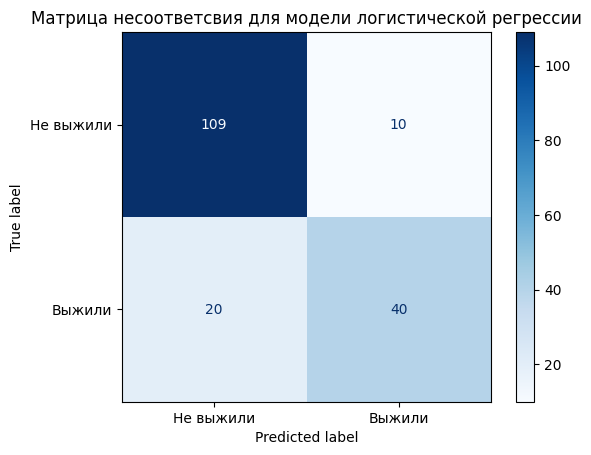

In [66]:
titanicLog=accuracy_score(Y_test,y_pred)
print(titanicLog)

confusionMatrixTitan=confusion_matrix(Y_test,y_pred)
plt.figure(figsize=(8,6))
disp = ConfusionMatrixDisplay(confusion_matrix=confusionMatrixTitan,display_labels=["Не выжили","Выжили"])
disp.plot(cmap="Blues")
plt.title("Матрица несоответсвия для модели логистической регрессии")
plt.show()

In [70]:
forestClass=RandomForestClassifier()
forestClass.fit(X_train, Y_train)

RandomForestClassifier()

[0 0 1 1 0 1 1 1 0 0 0 0 1 0 1 0 0 0 1 1 0 0 0 0 1 1 1 1 0 0 0 0 0 0 0 0 0
 1 0 0 1 1 1 0 0 0 0 1 0 0 1 0 1 0 0 1 0 0 0 1 0 0 0 0 0 1 1 1 1 0 0 0 0 0
 1 0 0 0 0 0 0 0 0 0 1 0 0 0 1 1 1 0 0 0 0 0 0 0 0 1 0 1 0 0 0 1 1 0 1 1 1
 0 0 1 1 1 0 0 0 0 1 1 0 1 0 0 0 1 0 1 0 0 0 0 1 0 0 0 0 0 1 0 1 1 0 0 0 0
 0 0 0 0 0 0 0 0 1 1 0 1 0 0 0 1 1 1 1 0 0 1 0 1 0 1 0 1 0 1 0]
0.8212290502793296


<Figure size 800x600 with 0 Axes>

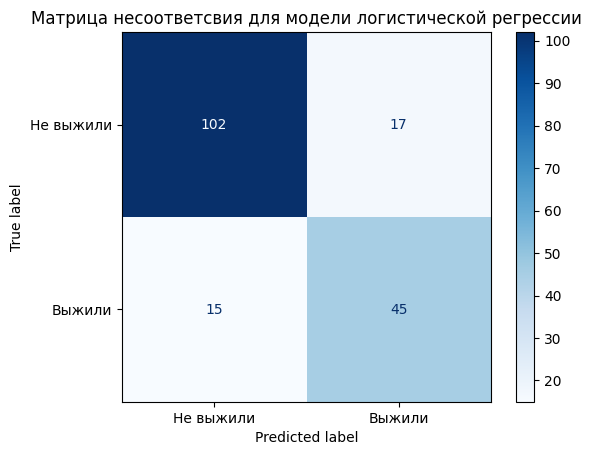

In [71]:
y_pred=forestClass.predict(X_test)
print(y_pred)
titanicLog=accuracy_score(Y_test,y_pred)
print(titanicLog)

confusionMatrixTitan=confusion_matrix(Y_test,y_pred)
plt.figure(figsize=(8,6))
disp = ConfusionMatrixDisplay(confusion_matrix=confusionMatrixTitan,display_labels=["Не выжили","Выжили"])
disp.plot(cmap="Blues")
plt.title("Матрица несоответсвия для случайного леса")
plt.show()

In [84]:
neighborsClass=KNeighborsClassifier(n_neighbors=4,algorithm = 'kd_tree')
neighborsClass.fit(X_train, Y_train)

KNeighborsClassifier(algorithm='kd_tree', n_neighbors=4)

[0 0 1 0 0 0 0 1 1 0 0 0 0 0 1 1 0 0 0 1 0 0 0 0 1 0 0 1 0 0 0 0 0 0 0 0 0
 1 0 0 1 0 1 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 1 0 0 0 0 0 1 0 1 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 1 0 0 0 1 0 1 0 0 0 0 0 0 0 0 1 1 1 0 0 0 0 1 0 1 1 0
 0 0 0 0 1 0 0 0 0 1 1 0 0 0 0 1 1 0 0 0 0 0 1 0 0 0 0 0 0 1 0 1 1 0 0 0 0
 0 1 0 0 0 0 0 0 0 1 0 1 0 0 0 1 1 0 0 0 1 1 0 1 0 0 0 0 0 0 0]
0.7597765363128491


<Figure size 800x600 with 0 Axes>

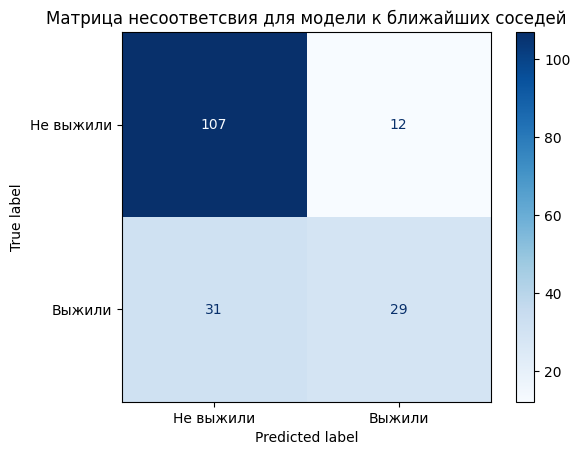

In [85]:
y_pred=neighborsClass.predict(X_test)
print(y_pred)
titanicLog=accuracy_score(Y_test,y_pred)
print(titanicLog)

confusionMatrixTitan=confusion_matrix(Y_test,y_pred)
plt.figure(figsize=(8,6))
disp = ConfusionMatrixDisplay(confusion_matrix=confusionMatrixTitan,display_labels=["Не выжили","Выжили"])
disp.plot(cmap="Blues")
plt.title("Матрица несоответсвия для модели к ближайших соседей")
plt.show()